In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_folder = Path(r"D:\electricity-tariff-optimisation")
processed_folder = project_folder / "data" / "processed"
figure_folder = project_folder / "reports" / "figures"
figure_folder.mkdir(parents=True, exist_ok=True)

customer_results = pd.read_csv(
    processed_folder / "customer_tariff_results_2013.csv",
    index_col="household_id",
)

segment_results = pd.read_csv(
    processed_folder / "validation_segment_outcomes_2013.csv",
    index_col="usage_segment",
)

cost_stress = pd.read_csv(
    processed_folder
    / "validation_protected_tariff_cost_stress_2013.csv"
)

assert len(customer_results) == 248
assert customer_results.index.is_unique
assert segment_results["households"].sum() == 248

print(f"Customer records loaded: {len(customer_results)}")
print(f"Customer segments loaded: {len(segment_results)}")
print(f"Cost stress scenarios loaded: {len(cost_stress)}")
print("Saved results loaded; optimisation was not rerun.")

Customer records loaded: 248
Customer segments loaded: 3
Cost stress scenarios loaded: 4
Saved results loaded; optimisation was not rerun.


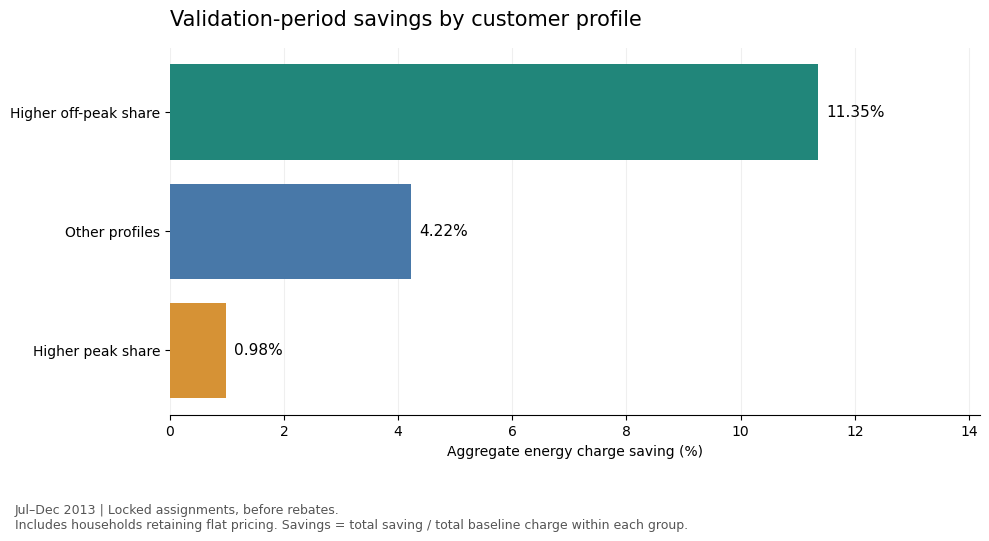

Figure saved: D:\electricity-tariff-optimisation\reports\figures\validation_savings_by_customer_profile.png


In [2]:
segment_order = [
    "Higher off-peak share",
    "Other profiles",
    "Higher peak share",
]

plot_data = segment_results.reindex(segment_order)

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    plot_data.index,
    plot_data["aggregate_saving_pct"],
    color=["#21867A", "#4878A8", "#D69235"],
)

ax.invert_yaxis()

for bar, (_, row) in zip(bars, plot_data.iterrows()):
    ax.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f'{row["aggregate_saving_pct"]:.2f}%',
        va="center",
        fontsize=11,
    )

ax.set_title(
    "Validation-period savings by customer profile",
    loc="left",
    fontsize=15,
    pad=16,
)

ax.set_xlabel("Aggregate energy charge saving (%)")
ax.set_ylabel("")
ax.set_xlim(
    0,
    plot_data["aggregate_saving_pct"].max() * 1.25,
)

ax.xaxis.grid(True, alpha=0.2)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

fig.text(
    0.02,
    0.03,
    "Jul–Dec 2013 | Locked assignments, before rebates.\n"
    "Includes households retaining flat pricing. "
    "Savings = total saving / total baseline charge within each group.",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0, 0.13, 1, 1])

figure_file = (
    figure_folder / "validation_savings_by_customer_profile.png"
)

fig.savefig(
    figure_file,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved: {figure_file}")

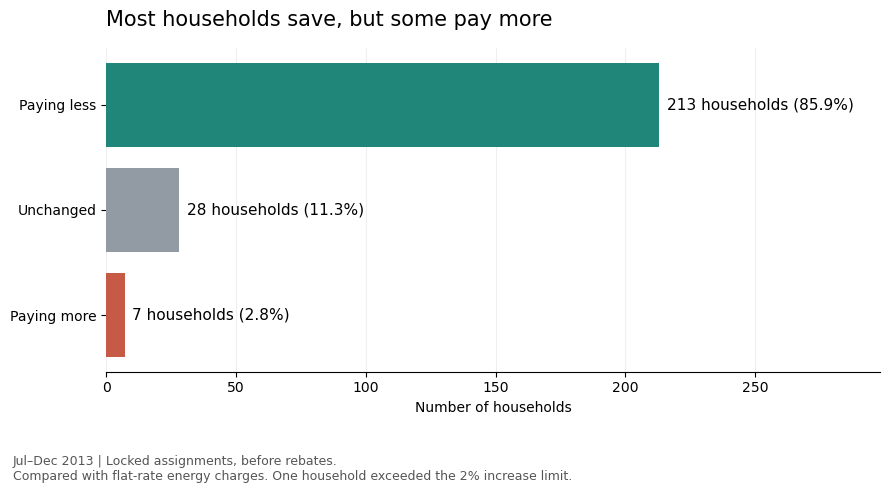

Figure saved: D:\electricity-tariff-optimisation\reports\figures\validation_customer_outcomes.png


In [3]:
tolerance = 1e-9

outcome_counts = pd.Series({
    "Paying less": int(
        (customer_results["saving_gbp"] > tolerance).sum()
    ),
    "Unchanged": int(
        (customer_results["saving_gbp"].abs() <= tolerance).sum()
    ),
    "Paying more": int(
        (customer_results["saving_gbp"] < -tolerance).sum()
    ),
})

assert outcome_counts.sum() == len(customer_results)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    outcome_counts.index,
    outcome_counts.values,
    color=["#21867A", "#929AA3", "#C65A46"],
)

ax.invert_yaxis()

for bar, count in zip(bars, outcome_counts.values):
    percentage = count / len(customer_results) * 100

    ax.text(
        bar.get_width() + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{count} households ({percentage:.1f}%)",
        va="center",
        fontsize=11,
    )

ax.set_title(
    "Most households save, but some pay more",
    loc="left",
    fontsize=15,
    pad=16,
)

ax.set_xlabel("Number of households")
ax.set_xlim(0, outcome_counts.max() * 1.4)
ax.xaxis.grid(True, alpha=0.2)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

fig.text(
    0.02,
    0.03,
    "Jul–Dec 2013 | Locked assignments, before rebates.\n"
    "Compared with flat-rate energy charges. "
    "One household exceeded the 2% increase limit.",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0, 0.13, 1, 1])

figure_file = (
    figure_folder / "validation_customer_outcomes.png"
)

fig.savefig(figure_file, dpi=200, bbox_inches="tight")
plt.show()

print(f"Figure saved: {figure_file}")

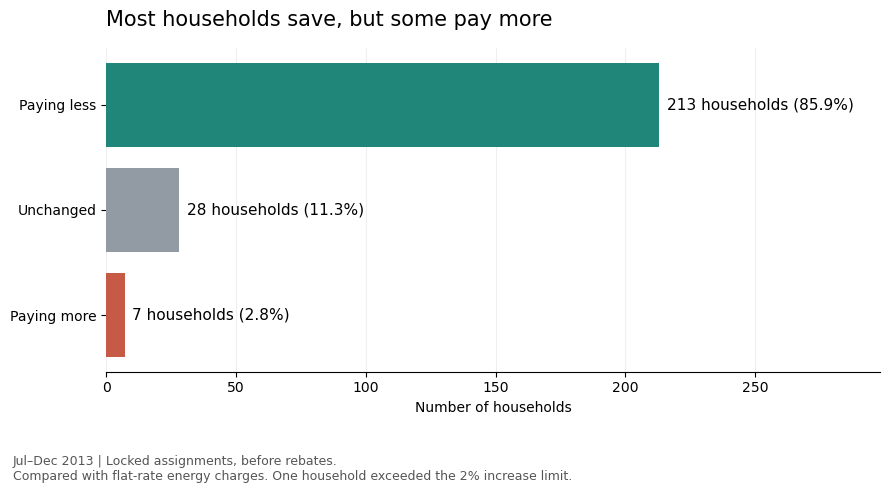

Figure saved: D:\electricity-tariff-optimisation\reports\figures\validation_customer_outcomes.png


In [4]:
tolerance = 1e-9

outcome_counts = pd.Series({
    "Paying less": int(
        (customer_results["saving_gbp"] > tolerance).sum()
    ),
    "Unchanged": int(
        (customer_results["saving_gbp"].abs() <= tolerance).sum()
    ),
    "Paying more": int(
        (customer_results["saving_gbp"] < -tolerance).sum()
    ),
})

assert outcome_counts.sum() == len(customer_results)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    outcome_counts.index,
    outcome_counts.values,
    color=["#21867A", "#929AA3", "#C65A46"],
)

ax.invert_yaxis()

for bar, count in zip(bars, outcome_counts.values):
    percentage = count / len(customer_results) * 100

    ax.text(
        bar.get_width() + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{count} households ({percentage:.1f}%)",
        va="center",
        fontsize=11,
    )

ax.set_title(
    "Most households save, but some pay more",
    loc="left",
    fontsize=15,
    pad=16,
)

ax.set_xlabel("Number of households")
ax.set_xlim(0, outcome_counts.max() * 1.4)
ax.xaxis.grid(True, alpha=0.2)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

fig.text(
    0.02,
    0.03,
    "Jul–Dec 2013 | Locked assignments, before rebates.\n"
    "Compared with flat-rate energy charges. "
    "One household exceeded the 2% increase limit.",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0, 0.13, 1, 1])

figure_file = (
    figure_folder / "validation_customer_outcomes.png"
)

fig.savefig(figure_file, dpi=200, bbox_inches="tight")
plt.show()

print(f"Figure saved: {figure_file}")

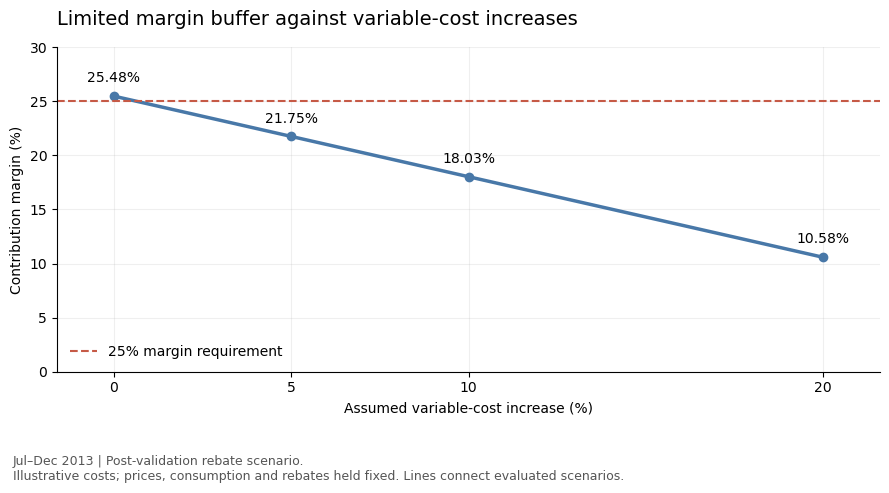

Figure saved: D:\electricity-tariff-optimisation\reports\figures\validation_variable_cost_sensitivity.png


In [5]:
plot_stress = cost_stress.sort_values("cost_increase_pct")

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    plot_stress["cost_increase_pct"],
    plot_stress["contribution_margin_pct"],
    marker="o",
    linewidth=2.5,
    color="#4878A8",
)

ax.axhline(
    25,
    color="#C65A46",
    linestyle="--",
    label="25% margin requirement",
)

for _, row in plot_stress.iterrows():
    ax.annotate(
        f'{row["contribution_margin_pct"]:.2f}%',
        (
            row["cost_increase_pct"],
            row["contribution_margin_pct"],
        ),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
    )

ax.set_title(
    "Limited margin buffer against variable-cost increases",
    loc="left",
    fontsize=14,
    pad=16,
)

ax.set_xlabel("Assumed variable-cost increase (%)")
ax.set_ylabel("Contribution margin (%)")
ax.set_xticks(plot_stress["cost_increase_pct"])
ax.set_ylim(0, 30)
ax.margins(x=0.08)
ax.grid(True, alpha=0.2)
ax.legend(loc="lower left", frameon=False)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.text(
    0.02,
    0.03,
    "Jul–Dec 2013 | Post-validation rebate scenario.\n"
    "Illustrative costs; prices, consumption and rebates held fixed. "
    "Lines connect evaluated scenarios.",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0, 0.13, 1, 1])

figure_file = (
    figure_folder / "validation_variable_cost_sensitivity.png"
)

fig.savefig(figure_file, dpi=200, bbox_inches="tight")
plt.show()

print(f"Figure saved: {figure_file}")

In [6]:
expected_figures = [
    "validation_savings_by_customer_profile.png",
    "validation_customer_outcomes.png",
    "validation_variable_cost_sensitivity.png",
]

for filename in expected_figures:
    figure_path = figure_folder / filename

    assert figure_path.is_file(), f"Missing figure: {filename}"
    assert figure_path.stat().st_size > 0, f"Empty figure: {filename}"

    print(f"Verified: {filename}")

print("All three presentation figures are available.")

Verified: validation_savings_by_customer_profile.png
Verified: validation_customer_outcomes.png
Verified: validation_variable_cost_sensitivity.png
All three presentation figures are available.
